# Video Games Sales Predictor

In [36]:
#Loading dataset
import pandas as pd

df = pd.read_csv("data/videogamesales.csv")

print("Dataset loaded")


Dataset loaded


In [37]:
#prints first five rows
df.head()

,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


In [38]:
#prints numbers of rows & columns
print("Rows:", df.shape[0])
print("Columns", df.shape[1])

Rows: 16719
Columns 16


In [39]:
#inspect first five rows
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16719 entries, 0 to 16718
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16717 non-null  str    
 1   Platform         16719 non-null  str    
 2   Year_of_Release  16450 non-null  float64
 3   Genre            16717 non-null  str    
 4   Publisher        16665 non-null  str    
 5   NA_Sales         16719 non-null  float64
 6   EU_Sales         16719 non-null  float64
 7   JP_Sales         16719 non-null  float64
 8   Other_Sales      16719 non-null  float64
 9   Global_Sales     16719 non-null  float64
 10  Critic_Score     8137 non-null   float64
 11  Critic_Count     8137 non-null   float64
 12  User_Score       10015 non-null  str    
 13  User_Count       7590 non-null   float64
 14  Developer        10096 non-null  str    
 15  Rating           9950 non-null   str    
dtypes: float64(9), str(7)
memory usage: 2.0 MB


In [40]:
#handle missing values
print("Missing values:")
print(df.isnull().sum())

Missing values:
Name                  2
Platform              0
Year_of_Release     269
Genre                 2
Publisher            54
NA_Sales              0
EU_Sales              0
JP_Sales              0
Other_Sales           0
Global_Sales          0
Critic_Score       8582
Critic_Count       8582
User_Score         6704
User_Count         9129
Developer          6623
Rating             6769
dtype: int64


In [41]:
#getting stats
df.describe()

,Year_of_Release,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Count
count,16450.000000,16719.000000,16719.000000,16719.000000,16719.000000,16719.000000,8137.000000,8137.000000,7590.000000
mean,2006.487356,0.263330,0.145025,0.077602,0.047332,0.533543,68.967679,26.360821,162.229908
std,5.878995,0.813514,0.503283,0.308818,0.186710,1.547935,13.938165,18.980495,561.282326
min,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000,13.000000,3.000000,4.000000
25%,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000,60.000000,12.000000,10.000000
50%,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000,71.000000,21.000000,24.000000
75%,2010.000000,0.240000,0.110000,0.040000,0.030000,0.470000,79.000000,36.000000,81.000000
max,2020.000000,41.360000,28.960000,10.220000,10.570000,82.530000,98.000000,113.000000,10665.000000


### Cleaning Data

In [42]:
#cleaning data
df["User_Score"] = pd.to_numeric(df["User_Score"], errors="coerce")

columns = ["Platform", "Genre", "Rating", "Year_of_Release", "Global_Sales",
           "Critic_Count", "User_Score", "User_Count", "Critic_Score"]
data = df[columns].dropna()
data.shape

(6826, 9)

### Exploring Data

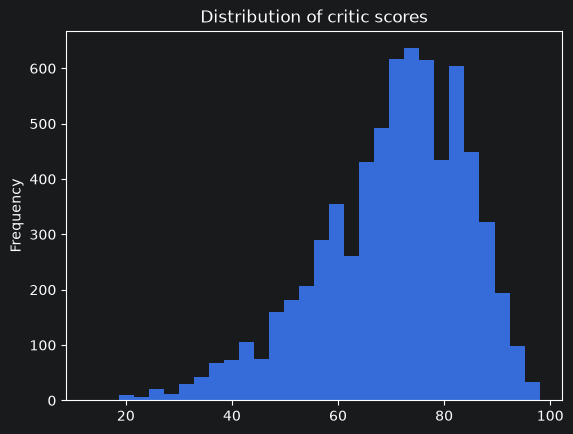

In [43]:
data["Critic_Score"].plot.hist(bins=30, title="Distribution of critic scores")
plt.show()

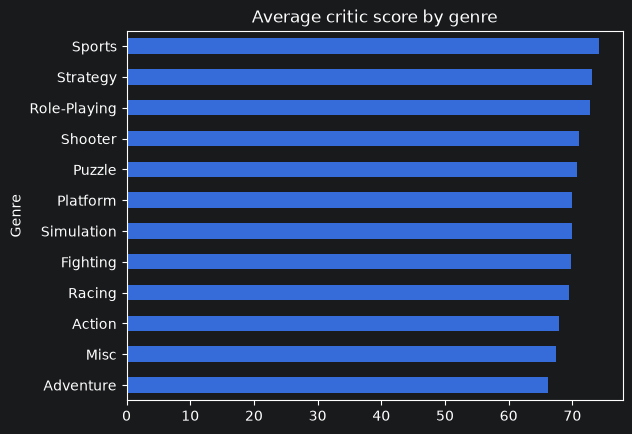

In [44]:
data.groupby("Genre")["Critic_Score"].mean().sort_values().plot.barh(title="Average critic score by genre")
plt.show()

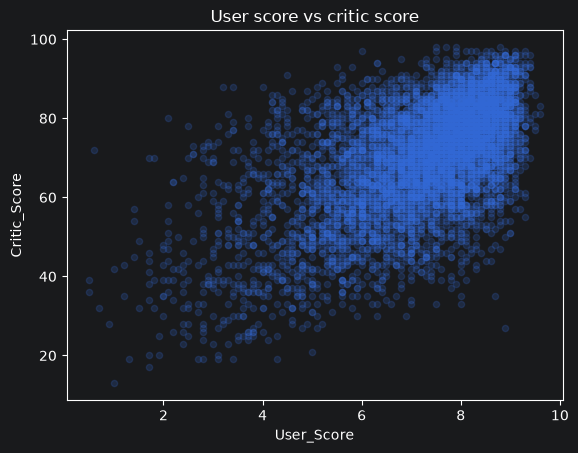

In [45]:
data.plot.scatter(x="User_Score", y="Critic_Score", alpha=0.2, title="User score vs critic score")
plt.show()

### Preparing features

In [46]:
from sklearn.model_selection import train_test_split

X = pd.get_dummies(data.drop(columns="Critic_Score"))
y = data["Critic_Score"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Training and Evaluating models

Uses Linear Regression and Random Forest

In [47]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

print("Linear Regression  MAE:", mean_absolute_error(y_test, lr_pred), " R2:", r2_score(y_test, lr_pred))
print("Random Forest      MAE:", mean_absolute_error(y_test, rf_pred), " R2:", r2_score(y_test, rf_pred))

Linear Regression  MAE: 7.753038321433702  R2: 0.5103829757150595
Random Forest      MAE: 6.838462664714495  R2: 0.6030215524228579


### Random Forest

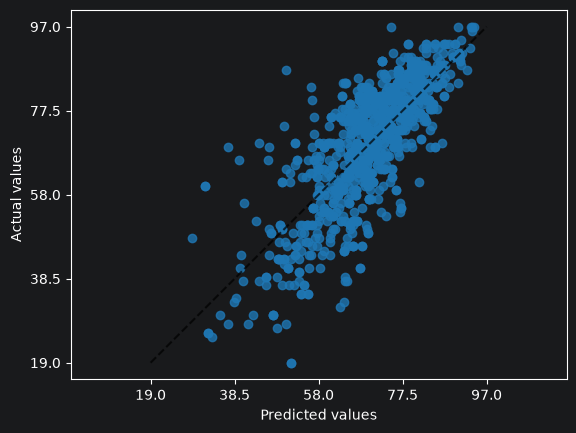

In [48]:
from sklearn.metrics import PredictionErrorDisplay

PredictionErrorDisplay.from_predictions(y_test, rf_pred, kind="actual_vs_predicted")
plt.show()

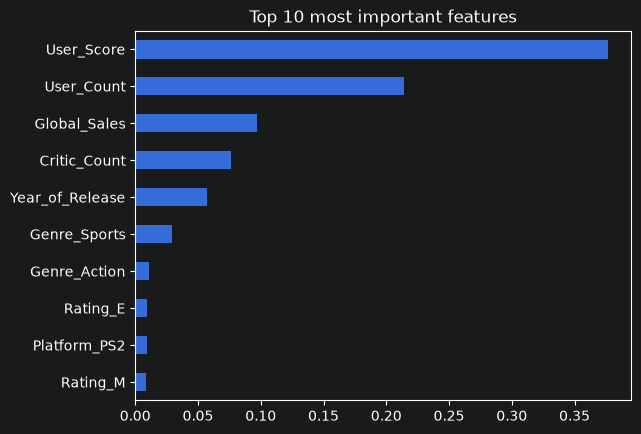

In [49]:
importances = pd.Series(rf.feature_importances_, index=X.columns)
importances.sort_values().tail(10).plot.barh(title="Top 10 most important features")
plt.show()

In [50]:
# compare a few predictions with the real scores
pd.DataFrame({"Actual": y_test, "Predicted": rf_pred.round(1)}).head(10)

,Actual,Predicted
146,94.0,93.3
3576,74.0,69.9
4840,61.0,64.2
15458,52.0,66.8
2464,62.0,56.0
14474,88.0,82.1
3617,68.0,65.6
15048,86.0,74.7
8353,69.0,62.9
6293,41.0,55.8
